# RQ05 — frequência de releases e taxa de falha

Sprint 3, parte B. Reexecução offline a partir do dataset congelado. Cada repositório tem o mesmo peso. Valores ausentes são excluídos somente do par necessário; zeros permanecem. A execução recalcula os resultados e confere a equivalência com os CSVs publicados.

In [1]:
from pathlib import Path
import sys
import json
from io import StringIO, BytesIO
import pandas as pd
from IPython.display import display, Image
import matplotlib.pyplot as plt

base = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "analises").is_dir())
if str(base) not in sys.path:
    sys.path.insert(0, str(base))
from analises.comum import carregar_dataset, sha256
from analises import rq05
from analises.artefatos import dispersao

df, origem = carregar_dataset(base / "data/dataset.csv")
referencia = base / "results/s03_b"
manifesto = json.loads((referencia / "manifesto.json").read_text(encoding="utf-8"))
assert origem == manifesto["origens"]
parametros = manifesto["parametros"]
print(f"Amostra: {len(df)} projetos; semente: {parametros['semente']}")

def conferir(nome, tabela):
    arquivo = referencia / f"{nome}.csv"
    assert sha256(arquivo) == manifesto["artefatos_sha256"][arquivo.name]
    calculada = pd.read_csv(StringIO(tabela.to_csv(index=False, float_format="%.17g")))
    publicada = pd.read_csv(arquivo)
    pd.testing.assert_frame_equal(calculada, publicada, check_dtype=False, rtol=1e-12, atol=1e-14)


def mostrar_figura(figura):
    buffer = BytesIO()
    figura.savefig(buffer, format="png", dpi=150, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(figura)


Amostra: 300 projetos; semente: 42


## Método e diferencial

Spearman bilateral para CFR (a) e (b). IC95% BCa com bootstrap **pareado** (9.999 reamostragens), permutação bilateral dos pareamentos (9.999) e Holm sobre os dois p-valores de permutação. Semente 42 e fluxos separados por variante/método. Leave-one-out retira um projeto por vez, sem selecionar exclusões para a análise principal.

[Spearman](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html) · [Bootstrap](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html) · [Permutação](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html)

In [2]:
resultado = rq05.analisar(df, semente=parametros["semente"], reamostragens=parametros["reamostragens"])
for nome in ("rq05_correlacoes", "rq05_influencia"):
    conferir(nome, resultado[nome])
display(resultado["rq05_correlacoes"].T)
display(resultado["exclusoes"])

,0,1
variante,cfr_a,cfr_b
n_total,300,300
n,300,289
n_excluidos,0,11
rho,0.01474,0.660229
p_spearman,0.799306,0.0
p_permutacao,0.8096,0.0002
ic95_inferior,-0.094737,0.58536
ic95_superior,0.1255,0.724381
status,ok,ok


,analise,fator,metrica,full_name,campo,motivo
0,RQ05,,cfr_b,Mithril-mine/libmdbx,cfr_b,evidencia_textual_insuficiente
1,RQ05,,cfr_b,Monica-Pass/Monica,cfr_b,evidencia_textual_insuficiente
2,RQ05,,cfr_b,Yazelix/nova,cfr_b,evidencia_textual_insuficiente
3,RQ05,,cfr_b,YumeYucca/YumeBox,cfr_b,evidencia_textual_insuficiente
4,RQ05,,cfr_b,caezium/burrow,cfr_b,evidencia_textual_insuficiente
5,RQ05,,cfr_b,guhcostan/mac-cleaner-cli,cfr_b,evidencia_textual_insuficiente
6,RQ05,,cfr_b,jithin-sabu/purge-app,cfr_b,evidencia_textual_insuficiente
7,RQ05,,cfr_b,moraroy/NonSteamLaunchers-On-Steam-Deck,cfr_b,evidencia_textual_insuficiente
8,RQ05,,cfr_b,nixopus/nixopus,cfr_b,evidencia_textual_insuficiente
9,RQ05,,cfr_b,rachelos/we-mp-rss,cfr_b,evidencia_textual_insuficiente


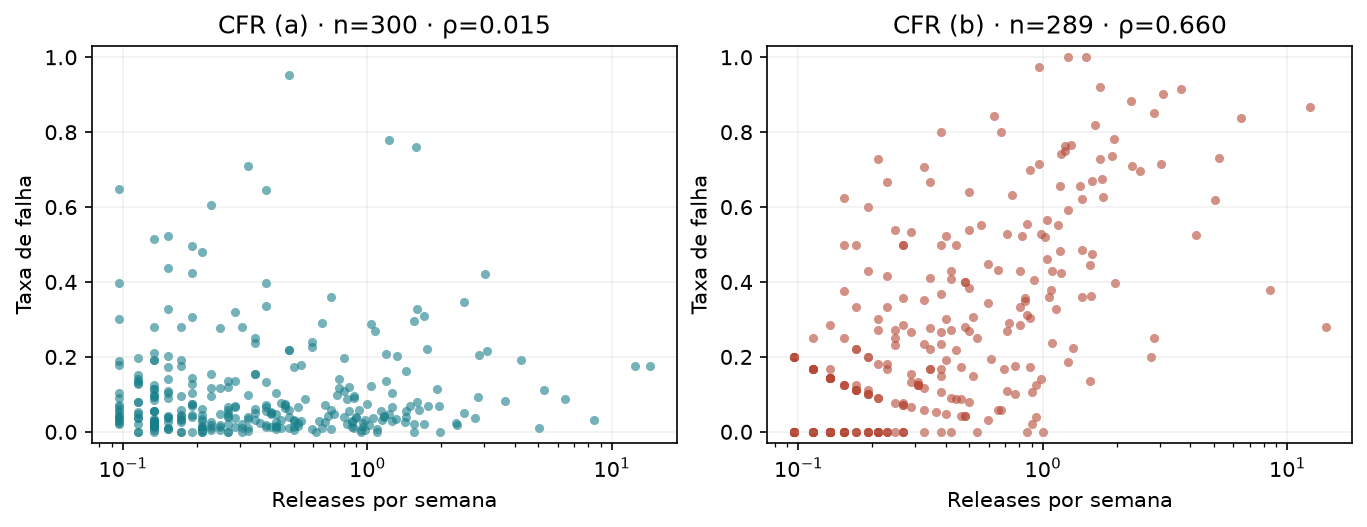

,variante,full_name,rho_sem_repo,delta_rho,mudou_sinal,status,influencia
122,cfr_a,dtcooper/raspotify,0.024075,0.009335,False,ok,0.009335
155,cfr_a,hlorenzi/customasm,0.023565,0.008826,False,ok,0.008826
142,cfr_a,google/dawn,0.006204,-0.008536,False,ok,0.008536
107,cfr_a,coollabsio/jean,0.006274,-0.008466,False,ok,0.008466
141,cfr_a,google/clusterfuzz,0.023050,0.008310,False,ok,0.008310
53,cfr_a,WenjieDu/PyPOTS,0.022914,0.008174,False,ok,0.008174
210,cfr_a,nixopus/nixopus,0.006578,-0.008161,False,ok,0.008161
538,cfr_b,remnawave/panel,0.667877,0.007648,False,ok,0.007648
218,cfr_a,open-logic/open-logic,0.007139,-0.007601,False,ok,0.007601
29,cfr_a,Mithril-mine/libmdbx,0.007139,-0.007601,False,ok,0.007601


In [3]:
mostrar_figura(dispersao(df, resultado["rq05_correlacoes"]))
display(resultado["rq05_influencia"].assign(influencia=lambda x: x.delta_rho.abs()).sort_values("influencia", ascending=False).head(10))

## Interpretação

H5 previa associação fraca e negativa. O proxy de CI apresenta correlação próxima de zero, com IC que inclui zero. O proxy de entrega apresenta associação positiva, preservada ao retirar qualquer projeto individual. H5 não é sustentada por estas análises.

Há um possível acoplamento entre frequência e a regra de falha: mais releases criam mais oportunidades de encontrar uma corretiva em sete dias. Essa explicação é uma hipótese metodológica, não um mecanismo causal demonstrado. Bootstrap e permutação não eliminam esse problema, o viés de seleção ou a incerteza da heurística. Os 11 CFR(b) ausentes não foram imputados. A generalização permanece limitada à amostra e aos proxies.